# Laboratoire — Évaluation des modèles en Computer Vision

Ce notebook met en pratique l’évaluation de quatre tâches : **classification d’images**, **détection d’objets**, **segmentation sémantique** et **segmentation d’instances**.

Pour chaque tâche, on suit le même fil conducteur :
1. préparer les données et les références (*Ground Truth*) ;
2. produire les prédictions du modèle ;
3. calculer les métriques adaptées ;
4. visualiser et interpréter les résultats.

Les sorties déjà présentes sont conservées. Les cellules de code ne sont pas réexécutées pendant cette mise en forme.

In [1]:
# Installer la bibliothèque nécessaire
!pip -q install ultralytics

# Importer les bibliothèques utilisées
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from ultralytics import YOLO

print("Environment ready!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Environment ready!


## 1. Classification d’images — jeu de données Digits

**Objectif :** entraîner un modèle qui attribue une classe à chaque image, puis mesurer la qualité de ses prédictions.

Le jeu de données `Digits` contient des images de chiffres réparties en **10 classes**. On sépare les données en un ensemble d’entraînement et un ensemble de test.

In [2]:
# Charger le jeu de données Digits
digits = load_digits()

X = digits.data
y = digits.target

# Séparer les données : 80 % pour l'entraînement, 20 % pour le test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Construire le modèle de classification
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

# Entraîner le modèle
model.fit(X_train, y_train)

# Effectuer les prédictions
y_pred = model.predict(X_test)

print("Classification model trained successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of classes:", len(np.unique(y)))

Classification model trained successfully!
Training samples: 1437
Testing samples: 360
Number of classes: 10


### 1.1 Évaluer les prédictions de classification

On calcule quatre métriques :
- **Accuracy** : proportion de prédictions correctes ;
- **Precision** : parmi les prédictions positives, proportion réellement positive ;
- **Recall** : parmi les exemples réellement positifs, proportion retrouvée ;
- **F1-score** : moyenne harmonique de la précision et du rappel.

Ici, `average="macro"` calcule chaque métrique par classe, puis fait la moyenne en donnant le même poids à chaque classe.

In [3]:
# Calculer les métriques d'évaluation

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro"
)

recall = recall_score(
    y_test, y_pred, average="macro"
)

f1 = f1_score(
    y_test, y_pred, average="macro"
)

# Afficher les résultats
print("Classification Evaluation")
print("-------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Classification Evaluation
-------------------------
Accuracy:  0.9722
Precision: 0.9721
Recall:    0.9719
F1-score:  0.9719


**Lecture des résultats :** l’Accuracy est de **97,22 %** et le F1-score macro de **97,19 %**. Les scores élevés et proches indiquent que le classifieur reconnaît correctement la grande majorité des chiffres, avec des performances globalement équilibrées entre les dix classes.

### 1.2 Lire la matrice de confusion

La matrice compare les **classes réelles** (lignes) aux **classes prédites** (colonnes). Les valeurs sur la diagonale correspondent aux prédictions correctes ; les valeurs hors diagonale montrent les confusions entre chiffres.

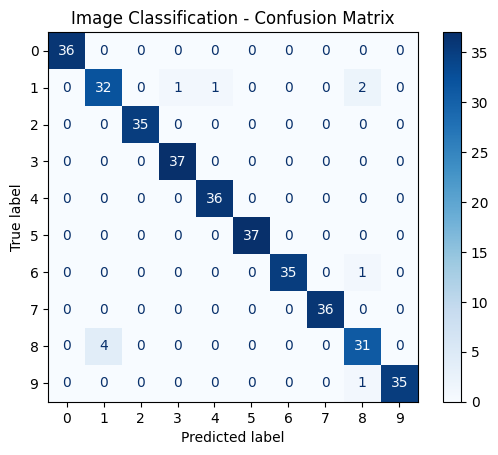

In [4]:
# Calculer la matrice de confusion
cm = confusion_matrix(y_test, y_pred)

# Afficher la matrice de confusion
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=digits.target_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Image Classification - Confusion Matrix")
plt.show()

**À retenir :** une diagonale dominante indique que la plupart des chiffres sont correctement classés. Les quelques valeurs hors diagonale signalent les chiffres que le modèle confond.

## 2. Détection d’objets — préparation du jeu de données Penn-Fudan

**Objectif :** détecter les piétons dans les images, puis comparer les boîtes prédites aux boîtes de référence.

On utilise le jeu de données **Penn-Fudan Pedestrian**, qui contient des images de personnes et leurs masques d’annotation.

In [5]:
# Télécharger le jeu de données Penn-Fudan
!wget -q https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip \
    -O /content/PennFudanPed.zip

# Extraire le jeu de données
!unzip -q -o /content/PennFudanPed.zip -d /content/data

print("Penn-Fudan dataset downloaded successfully!")

Penn-Fudan dataset downloaded successfully!


### 2.1 Organiser les images et les masques

Cette étape définit les dossiers du jeu de données et récupère les chemins des fichiers image et masque. Chaque image possède un masque associé.

In [6]:
import glob
import os

# Définir les dossiers du jeu de données
DATASET_DIR = "/content/data/PennFudanPed"

IMAGE_DIR = os.path.join(DATASET_DIR, "PNGImages")
MASK_DIR = os.path.join(DATASET_DIR, "PedMasks")

# Récupérer les chemins des images et des masques
image_files = sorted(glob.glob(IMAGE_DIR + "/*.png"))
mask_files = sorted(glob.glob(MASK_DIR + "/*.png"))

print("Number of images:", len(image_files))
print("Number of masks:", len(mask_files))

print("\nFirst image:", os.path.basename(image_files[0]))
print("First mask:", os.path.basename(mask_files[0]))

Number of images: 170
Number of masks: 170

First image: FudanPed00001.png
First mask: FudanPed00001_mask.png


### 2.2 Préparer les annotations de référence (*Ground Truth*)

Avant d'évaluer les modèles, on construit une structure `ground_truth` à partir des masques d'instances Penn-Fudan.

Pour chaque image, cette structure contient :
- `boxes` : une boîte par personne, au format `[x_min, y_min, x_max, y_max]` ;
- `masks` : un masque binaire par personne, avec `True` pour les pixels de cette instance.

Chaque valeur non nulle du masque original identifie une instance distincte. Cette préparation est nécessaire aux évaluations de détection et de segmentation d'instances.

In [7]:
from PIL import Image

# Construire les annotations Ground Truth pour toutes les images

ground_truth = {}
total_gt_instances = 0

for image_path in image_files:

    filename = os.path.basename(image_path)
    mask_filename = filename.replace(".png", "_mask.png")
    mask_path = os.path.join(MASK_DIR, mask_filename)

    # Vérifier que le masque associé à l'image existe
    if not os.path.isfile(mask_path):
        raise FileNotFoundError(
            f"Masque Ground Truth introuvable pour {filename}: {mask_path}"
        )

    # Lire les dimensions de l'image et le masque d'instances original
    with Image.open(image_path) as image:
        image_width, image_height = image.size

    with Image.open(mask_path) as mask_image:
        instance_map = np.array(mask_image)

    # Le masque Penn-Fudan doit être une image à étiquettes (2D)
    if instance_map.ndim != 2:
        raise ValueError(
            f"Le masque {mask_filename} doit être en niveaux d'étiquettes 2D."
        )

    if instance_map.shape != (image_height, image_width):
        raise ValueError(
            f"Dimensions incompatibles pour {filename}: "
            f"image={(image_height, image_width)}, "
            f"masque={instance_map.shape}"
        )

    # Récupérer les identifiants des instances (0 correspond au fond)
    instance_ids = np.unique(instance_map)
    instance_ids = instance_ids[instance_ids != 0]

    instance_masks = []
    boxes = []

    for instance_id in instance_ids:

        # Extraire le masque binaire de cette personne
        binary_mask = instance_map == instance_id
        y_indices, x_indices = np.where(binary_mask)

        if x_indices.size == 0:
            continue

        # Calculer la boîte englobante au format XYXY
        x_min = int(x_indices.min())
        y_min = int(y_indices.min())
        x_max = int(x_indices.max()) + 1
        y_max = int(y_indices.max()) + 1

        boxes.append([x_min, y_min, x_max, y_max])
        instance_masks.append(binary_mask.astype(bool))

    if not instance_masks:
        raise ValueError(
            f"Aucune instance n'a été trouvée dans le masque {mask_filename}."
        )

    # Enregistrer les boîtes et les masques sous le nom de l'image
    ground_truth[filename] = {
        "boxes": np.asarray(boxes, dtype=np.float32).reshape(-1, 4),
        "masks": instance_masks
    }

    total_gt_instances += len(instance_masks)


# Vérifier que toutes les images possèdent leurs annotations
if len(ground_truth) != len(image_files):
    raise RuntimeError(
        "Le nombre d'annotations Ground Truth ne correspond pas "
        "au nombre d'images."
    )

print("Ground Truth annotations prepared successfully!")
print("Images annotated:", len(ground_truth))
print("Total Ground Truth instances:", total_gt_instances)

# Vérifier la structure créée sur la première image
first_filename = os.path.basename(image_files[0])

print("\nExample image:", first_filename)
print("Bounding boxes shape:", ground_truth[first_filename]["boxes"].shape)
print("Number of instance masks:", len(ground_truth[first_filename]["masks"]))
print("Mask dimensions:", ground_truth[first_filename]["masks"][0].shape)


Ground Truth annotations prepared successfully!
Images annotated: 170
Total Ground Truth instances: 423

Example image: FudanPed00001.png
Bounding boxes shape: (2, 4)
Number of instance masks: 2
Mask dimensions: (536, 559)


### 2.3 Produire les détections avec YOLO11n

On charge le modèle pré-entraîné **YOLO11n** et on l’applique aux 170 images. Le modèle est limité à la classe `person` (classe 0).

Le seuil de confiance est volontairement très bas (`conf=0.001`) afin de conserver un grand nombre de prédictions pour l’évaluation AP, qui classe ensuite les détections selon leur score.

In [8]:
# Charger le modèle YOLO11n pré-entraîné
detector = YOLO("yolo11n.pt")

# Effectuer la détection sur les 170 images
detection_results = detector.predict(
    source=image_files,
    conf=0.001,
    iou=0.7,
    classes=[0],
    max_det=300,
    batch=16,
    verbose=False
)

# Compter toutes les personnes détectées
total_predictions = sum(
    len(result.boxes)
    for result in detection_results
)

print("Object Detection completed!")
print("Images processed:", len(detection_results))
print("Total predicted pedestrians:", total_predictions)

Object Detection completed!
Images processed: 170
Total predicted pedestrians: 9216


### 2.4 Visualiser une prédiction

On affiche le résultat de YOLO11n sur la première image. Les rectangles représentent les personnes détectées et les scores indiquent le niveau de confiance associé à chaque prédiction.

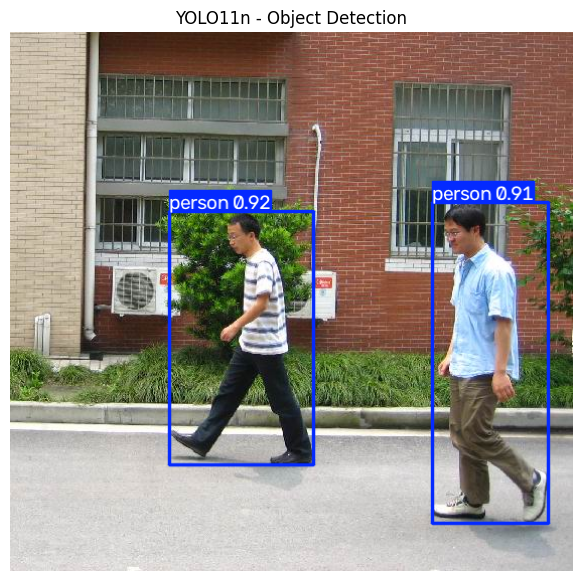

Predicted pedestrians: 2


In [22]:
# Afficher les détections avec un seuil de confiance de 0.25
result = detector.predict(
    source=image_files[0],
    conf=0.25,
    iou=0.7,
    classes=[0],
    verbose=False
)[0]

annotated = result.plot()

plt.figure(figsize=(9, 7))
plt.imshow(annotated[:, :, ::-1])
plt.title("YOLO11n - Object Detection")
plt.axis("off")
plt.show()

print("Predicted pedestrians:", len(result.boxes))

**Annotations de référence :** la variable `ground_truth` a été construite dans la cellule précédente à partir des masques d'instances Penn-Fudan. Pour chaque image, elle contient les boîtes de référence (`boxes`) et les masques individuels (`masks`).

In [10]:
# Calculer l'IoU entre deux bounding boxes
def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
    area2 = (box2[2]-box2[0]) * (box2[3]-box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


# Définir les seuils d'évaluation
CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50

TP = 0
FP = 0
FN = 0

# Évaluer toutes les images
for image_path, result in zip(image_files, detection_results):

    filename = os.path.basename(image_path)

    gt_boxes = ground_truth[filename]["boxes"]

    pred_boxes = result.boxes.xyxy.cpu().numpy()
    pred_scores = result.boxes.conf.cpu().numpy()

    # Conserver les prédictions dont le score dépasse le seuil de confiance
    valid = np.where(pred_scores >= CONF_THRESHOLD)[0]

    # Trier les prédictions par score de confiance décroissant
    valid = valid[np.argsort(pred_scores[valid])[::-1]]

    matched_gt = set()

    for idx in valid:

        pred_box = pred_boxes[idx]

        # Rechercher la boîte de référence non associée qui présente le meilleur IoU
        best_iou = 0
        best_gt = -1

        for gt_idx, gt_box in enumerate(gt_boxes):

            if gt_idx in matched_gt:
                continue

            iou = calculate_iou(pred_box, gt_box)

            if iou > best_iou:
                best_iou = iou
                best_gt = gt_idx

        # Associer la prédiction à la boîte de référence si le seuil d'IoU est atteint
        if best_iou >= IOU_THRESHOLD:
            TP += 1
            matched_gt.add(best_gt)
        else:
            FP += 1

    # Compter les objets de référence qui n'ont pas été détectés
    FN += len(gt_boxes) - len(matched_gt)


# Calculer les métriques finales
precision_det = TP / (TP + FP) if TP + FP else 0
recall_det = TP / (TP + FN) if TP + FN else 0

f1_det = (
    2 * precision_det * recall_det /
    (precision_det + recall_det)
    if precision_det + recall_det else 0
)

print("OBJECT DETECTION EVALUATION")
print("---------------------------")
print("TP:", TP)
print("FP:", FP)
print("FN:", FN)

print(f"Precision: {precision_det:.4f}")
print(f"Recall:    {recall_det:.4f}")
print(f"F1-score:  {f1_det:.4f}")

OBJECT DETECTION EVALUATION
---------------------------
TP: 423
FP: 263
FN: 0
Precision: 0.6166
Recall:    1.0000
F1-score:  0.7628


**Lecture des résultats :** le rappel de **1,0000** indique que les 423 objets de référence ont été retrouvés au seuil choisi. La précision de **0,6166** montre toutefois qu’un nombre important de boîtes supplémentaires sont comptées comme faux positifs. Le F1-score combine ces deux aspects.

### 2.6 Calculer l’AP@0.50

La fonction rassemble les détections de toutes les images, les trie par score de confiance et les associe aux boîtes de référence.

Elle calcule ensuite la précision et le rappel cumulés, puis l’**Average Precision (AP)** avec une interpolation sur 101 niveaux de rappel.

Comme le laboratoire évalue une seule classe (`person`), **AP@0.50 et mAP@0.50 ont ici la même valeur**.

In [11]:
def calculate_ap(iou_threshold):

    detections = []

    # Rassembler les prédictions de toutes les images
    for img_idx, result in enumerate(detection_results):

        boxes = result.boxes.xyxy.cpu().numpy()
        scores = result.boxes.conf.cpu().numpy()

        for box, score in zip(boxes, scores):
            detections.append((score, img_idx, box))

    # Trier les prédictions par score de confiance décroissant
    detections.sort(key=lambda x: x[0], reverse=True)

    matched_gt = [set() for _ in image_files]

    tp_flags = []
    fp_flags = []

    total_gt = sum(
        len(ground_truth[os.path.basename(path)]["boxes"])
        for path in image_files
    )

    # Associer chaque prédiction à un objet de référence non encore associé
    for score, img_idx, pred_box in detections:

        filename = os.path.basename(image_files[img_idx])
        gt_boxes = ground_truth[filename]["boxes"]

        unmatched = [
            j for j in range(len(gt_boxes))
            if j not in matched_gt[img_idx]
        ]

        if unmatched:

            ious = [
                calculate_iou(pred_box, gt_boxes[j])
                for j in unmatched
            ]

            best_pos = np.argmax(ious)
            best_iou = ious[best_pos]

            if best_iou >= iou_threshold:
                tp_flags.append(1)
                fp_flags.append(0)
                matched_gt[img_idx].add(unmatched[best_pos])

            else:
                tp_flags.append(0)
                fp_flags.append(1)

        else:
            tp_flags.append(0)
            fp_flags.append(1)

    # Calculer la précision et le rappel cumulés
    tp_cum = np.cumsum(tp_flags)
    fp_cum = np.cumsum(fp_flags)

    recalls = tp_cum / total_gt

    precisions = tp_cum / (tp_cum + fp_cum)

    # Calculer l'AP interpolée sur 101 niveaux de rappel
    recall_levels = np.linspace(0, 1, 101)

    interpolated_precision = []

    for r in recall_levels:

        valid = precisions[recalls >= r]

        interpolated_precision.append(
            np.max(valid) if len(valid) else 0
        )

    ap = np.mean(interpolated_precision)

    return ap, recalls, precisions


# Calculer l'AP avec un seuil d'IoU de 0,50
ap50, recalls, precisions = calculate_ap(0.50)

print(f"AP@0.50: {ap50:.4f}")

# Une seule classe est évaluée : person
print(f"mAP@0.50: {ap50:.4f}")

AP@0.50: 0.9640
mAP@0.50: 0.9640


### 2.7 Évaluation de type COCO : AP de 0,50 à 0,95

On répète le calcul de l’AP pour dix seuils d’IoU, de **0,50 à 0,95** avec un pas de 0,05.

La moyenne de ces dix AP donne le score COCO-style **mAP@0.50:0.95**. Plus le seuil d’IoU augmente, plus la localisation exigée est précise.

In [12]:
# Évaluer l'AP sur 10 seuils d'IoU
iou_thresholds = np.arange(0.50, 0.96, 0.05)

ap_values = []

for threshold in iou_thresholds:

    ap, _, _ = calculate_ap(float(threshold))
    ap_values.append(ap)

    print(f"AP@{threshold:.2f}: {ap:.4f}")

# Calculer la moyenne des AP sur les seuils d'IoU
map_50_95 = np.mean(ap_values)

print("\nCOCO-style evaluation")
print(f"mAP@0.50:0.95 = {map_50_95:.4f}")

AP@0.50: 0.9640
AP@0.55: 0.9611
AP@0.60: 0.9578
AP@0.65: 0.9444
AP@0.70: 0.9435
AP@0.75: 0.9299
AP@0.80: 0.8993
AP@0.85: 0.8613
AP@0.90: 0.7326
AP@0.95: 0.3935

COCO-style evaluation
mAP@0.50:0.95 = 0.8587


**Lecture des résultats :** l’AP@0.50 vaut **0,9640**, tandis que le mAP@0.50:0.95 vaut **0,8587**. La baisse avec des seuils d’IoU plus stricts indique que certaines boîtes détectent bien les objets, mais les localisent moins précisément lorsque l’exigence de recouvrement augmente.

### 2.8 Tracer la courbe Precision–Recall

La courbe montre l’évolution de la précision en fonction du rappel lorsque le seuil de confiance varie, avec un seuil d’IoU fixé à **0,50**.

Le point rouge représente le fonctionnement au seuil de confiance de **0,25**, utilisé dans le calcul TP/FP/FN précédent.

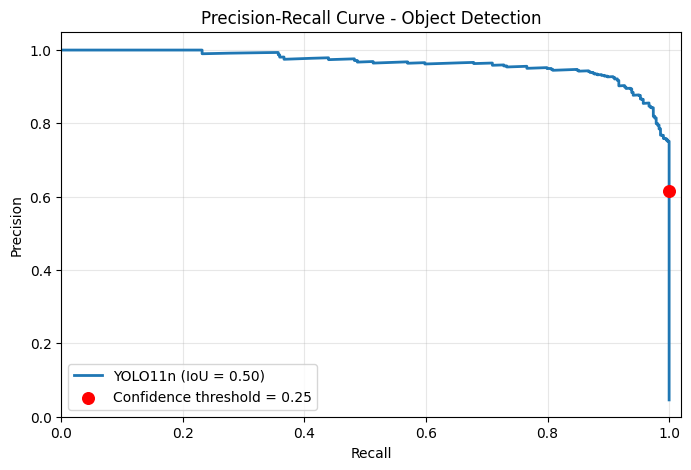

In [13]:
# Tracer la courbe précision-rappel (Precision–Recall)
plt.figure(figsize=(8, 5))

plt.plot(
    recalls,
    precisions,
    linewidth=2,
    label="YOLO11n (IoU = 0.50)"
)

# Marquer le point correspondant au seuil de confiance de 0,25
plt.scatter(
    recall_det,
    precision_det,
    color="red",
    s=70,
    label="Confidence threshold = 0.25",
    zorder=5
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Object Detection")

plt.xlim(0, 1.02)
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 3. Segmentation sémantique — évaluer les pixels

**Objectif :** comparer les pixels identifiés comme appartenant à la classe « personne » entre le masque prédit et le masque de référence.

On utilise le modèle **YOLO11n-seg** pour produire des masques d’instances sur les 170 images. Pour la segmentation sémantique, les masques individuels prédits sont ensuite fusionnés en un seul masque binaire « personne / fond ».

In [14]:
# Charger le modèle de segmentation pré-entraîné
segmenter = YOLO("yolo11n-seg.pt")

# Produire les masques prédits pour les 170 images
segmentation_results = segmenter.predict(
    source=image_files,
    conf=0.001,
    iou=0.7,
    classes=[0],
    max_det=300,
    batch=8,
    retina_masks=True,
    verbose=False
)

print("Segmentation predictions completed!")
print("Images processed:", len(segmentation_results))

Segmentation predictions completed!
Images processed: 170


### 3.1 Comparer visuellement les masques sémantiques

Sur une image, on affiche côte à côte :
- l’image originale ;
- le masque sémantique de référence ;
- le masque sémantique prédit.

La fusion des masques d’instances permet de comparer la présence de la classe « personne » pixel par pixel, sans distinguer les piétons entre eux.

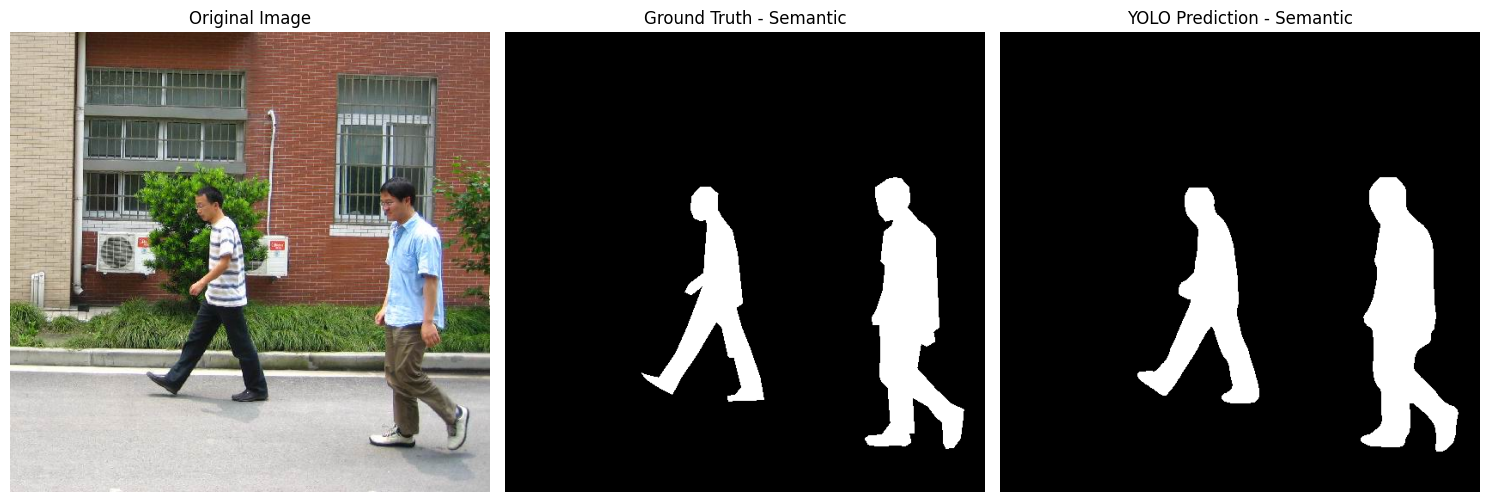

Ground Truth person pixels: 28962
Predicted person pixels: 32449


In [15]:
# Sélectionner une image pour visualiser les masques
idx = 0

filename = os.path.basename(image_files[idx])
mask_path = os.path.join(
    MASK_DIR,
    filename.replace(".png", "_mask.png")
)

# Construire le masque sémantique de référence
gt_mask = np.array(
    Image.open(mask_path).convert("L")
)

gt_semantic = (gt_mask > 0).astype(np.uint8)

# Construire le masque sémantique prédit
result = segmentation_results[idx]

if result.masks is not None:

    predicted_instances = result.masks.data.cpu().numpy()

    # Fusionner les masques d'instances en un seul masque de classe
    pred_semantic = np.any(
        predicted_instances > 0.5,
        axis=0
    ).astype(np.uint8)

else:
    pred_semantic = np.zeros_like(gt_semantic)

# Afficher l'image originale et les deux masques
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(Image.open(image_files[idx]))
axes[0].set_title("Original Image")

axes[1].imshow(gt_semantic, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground Truth - Semantic")

axes[2].imshow(pred_semantic, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("YOLO Prediction - Semantic")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Ground Truth person pixels:", gt_semantic.sum())
print("Predicted person pixels:", pred_semantic.sum())

### 3.2 Évaluer la segmentation au niveau des pixels

On compare les pixels prédits aux pixels de référence, en considérant « personne » et « arrière-plan » comme les deux classes.

On présente uniquement les quatre métriques de la diapositive : **IoU** (pour chaque classe), **mIoU** (moyenne des IoU), **Dice** (recouvrement entre les masques) et **Pixel Accuracy** (proportion de pixels correctement classés).

In [16]:
# Initialiser les compteurs globaux au niveau des pixels
TP_sem = 0
FP_sem = 0
FN_sem = 0
TN_sem = 0

for image_path, result in zip(image_files, segmentation_results):

    filename = os.path.basename(image_path)

    # Construire le masque sémantique de référence
    mask_path = os.path.join(
        MASK_DIR,
        filename.replace(".png", "_mask.png")
    )

    gt_mask = np.array(
        Image.open(mask_path).convert("L")
    )

    gt = gt_mask > 0

    # Construire le masque sémantique prédit
    if result.masks is not None:

        masks = result.masks.data.cpu().numpy()

        pred = np.any(masks > 0.5, axis=0)

    else:
        pred = np.zeros_like(gt)

    # Harmoniser les dimensions du masque prédit et du masque de référence
    if pred.shape != gt.shape:
        pred = cv2.resize(
            pred.astype(np.uint8),
            (gt.shape[1], gt.shape[0]),
            interpolation=cv2.INTER_NEAREST
        ).astype(bool)

    # Compter les TP, FP, FN et TN au niveau des pixels
    TP_sem += np.sum(gt & pred)
    FP_sem += np.sum(~gt & pred)
    FN_sem += np.sum(gt & ~pred)
    TN_sem += np.sum(~gt & ~pred)


# 1. Pixel Accuracy : proportion de pixels correctement classés
pixel_accuracy = (
    (TP_sem + TN_sem) /
    (TP_sem + TN_sem + FP_sem + FN_sem)
)

# 2. IoU de chaque classe
iou_person = (
    TP_sem / (TP_sem + FP_sem + FN_sem)
    if TP_sem + FP_sem + FN_sem else 0
)

iou_background = (
    TN_sem / (TN_sem + FP_sem + FN_sem)
    if TN_sem + FP_sem + FN_sem else 0
)

# 3. mIoU : moyenne des IoU des deux classes
miou = (iou_person + iou_background) / 2

# 4. Dice : équivalent au F1-score pour cette segmentation binaire
dice_sem = (
    2 * TP_sem / (2 * TP_sem + FP_sem + FN_sem)
    if 2 * TP_sem + FP_sem + FN_sem else 0
)


print("SEMANTIC SEGMENTATION EVALUATION")
print("--------------------------------")
print(f"IoU (Person):       {iou_person:.4f}")
print(f"IoU (Background):   {iou_background:.4f}")
print(f"mIoU:               {miou:.4f}")
print(f"Dice:               {dice_sem:.4f}")
print(f"Pixel Accuracy:     {pixel_accuracy:.4f}")


SEMANTIC SEGMENTATION EVALUATION
--------------------------------
IoU (Person):       0.6478
IoU (Background):   0.8932
mIoU:               0.7705
Dice:               0.7862
Pixel Accuracy:     0.9107


**Lecture des résultats :** la Pixel Accuracy atteint **0,9107**, la mIoU **0,7705** et le Dice **0,7862**. L’IoU de la personne (**0,6478**) est plus faible que celle du fond (**0,8932**) : le modèle segmente donc moins précisément les personnes que l’arrière-plan.

## 4. Segmentation d’instances — évaluer chaque objet séparément

**Objectif :** vérifier si le modèle retrouve chaque piéton avec un masque individuel suffisamment proche de son masque de référence.

Contrairement à la segmentation sémantique, deux personnes de la même classe doivent rester deux instances distinctes.

Predicted instances: 3


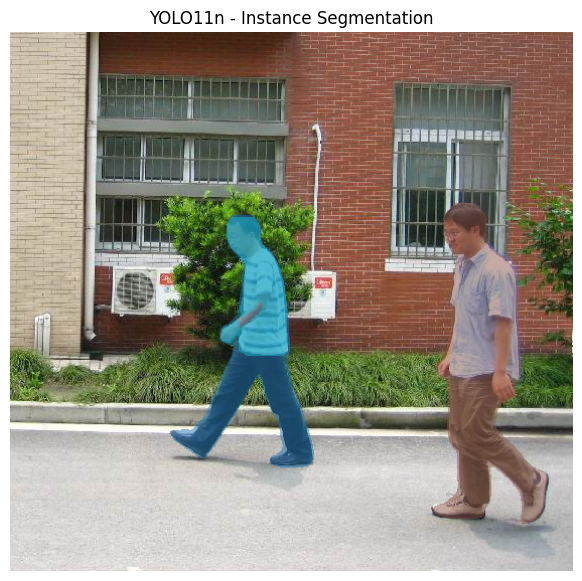

In [17]:
# Sélectionner la première image
idx = 0
result = segmentation_results[idx]

# Préparer l'image originale
original = result.orig_img[:, :, ::-1].copy()
overlay = original.astype(float).copy()

# Superposer les masques prédits, un par instance
if result.masks is not None:

    masks = result.masks.data.cpu().numpy()
    colors = plt.cm.tab10(np.linspace(0, 1, len(masks)))

    for i, mask in enumerate(masks):

        binary_mask = mask > 0.5
        color = np.array(colors[i][:3]) * 255

        overlay[binary_mask] = (
            0.5 * overlay[binary_mask]
            + 0.5 * color
        )

    print("Predicted instances:", len(masks))

# Afficher le résultat
plt.figure(figsize=(9, 7))
plt.imshow(overlay.astype(np.uint8))
plt.title("YOLO11n - Instance Segmentation")
plt.axis("off")
plt.show()

### 4.1 Associer les masques prédits aux instances de référence

On calcule le **Mask IoU** entre chaque masque prédit et les masques de référence. Une association est acceptée si le score atteint **0,50**.

Les prédictions sont filtrées avec un seuil de confiance de **0,25**, puis triées par score décroissant. Chaque instance réelle ne peut être associée qu’une seule fois.

In [18]:
# Calculer l'IoU entre deux masques
def calculate_mask_iou(mask1, mask2):

    intersection = np.logical_and(mask1, mask2).sum()
    union = np.logical_or(mask1, mask2).sum()

    return intersection / union if union > 0 else 0


# Définir les seuils d'évaluation
MASK_CONF_THRESHOLD = 0.25
MASK_IOU_THRESHOLD = 0.50

TP_mask = 0
FP_mask = 0
FN_mask = 0

matched_ious = []
total_predictions = 0

# Évaluer toutes les images
for image_path, result in zip(image_files, segmentation_results):

    filename = os.path.basename(image_path)

    gt_masks = ground_truth[filename]["masks"]

    if result.masks is None:
        continue

    pred_masks = result.masks.data.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()

    # Conserver les prédictions dont le score dépasse le seuil de confiance
    valid = np.where(scores >= MASK_CONF_THRESHOLD)[0]

    valid = valid[
        np.argsort(scores[valid])[::-1]
    ]

    total_predictions += len(valid)

    matched_gt = set()

    for idx in valid:

        pred_mask = pred_masks[idx] > 0.5

        # Harmoniser les dimensions du masque prédit et du masque de référence
        if pred_mask.shape != gt_masks[0].shape:
            pred_mask = cv2.resize(
                pred_mask.astype(np.uint8),
                (gt_masks[0].shape[1], gt_masks[0].shape[0]),
                interpolation=cv2.INTER_NEAREST
            ).astype(bool)

        best_iou = 0
        best_gt = -1

        # Rechercher le masque de référence non associé avec le meilleur IoU
        for gt_idx, gt_mask in enumerate(gt_masks):

            if gt_idx in matched_gt:
                continue

            iou = calculate_mask_iou(
                pred_mask,
                gt_mask
            )

            if iou > best_iou:
                best_iou = iou
                best_gt = gt_idx

        # Associer la prédiction au masque de référence si le seuil est atteint
        if best_iou >= MASK_IOU_THRESHOLD:

            TP_mask += 1
            matched_gt.add(best_gt)
            matched_ious.append(best_iou)

        else:
            FP_mask += 1

    # Compter les instances de référence non retrouvées
    FN_mask += len(gt_masks) - len(matched_gt)


# Calculer les métriques finales
precision_mask = TP_mask / (TP_mask + FP_mask) if TP_mask + FP_mask else 0

recall_mask = TP_mask / (TP_mask + FN_mask) if TP_mask + FN_mask else 0

f1_mask = (
    2 * precision_mask * recall_mask /
    (precision_mask + recall_mask)
    if precision_mask + recall_mask else 0
)

mean_mask_iou = np.mean(matched_ious) if matched_ious else 0


print("INSTANCE SEGMENTATION EVALUATION")
print("--------------------------------")
print("Ground Truth instances:", sum(len(ground_truth[os.path.basename(path)]["masks"]) for path in image_files))
print("Predicted instances:", total_predictions)

print("TP:", TP_mask)
print("FP:", FP_mask)
print("FN:", FN_mask)

print(f"Mean Mask IoU: {mean_mask_iou:.4f}")
print(f"Precision:     {precision_mask:.4f}")
print(f"Recall:        {recall_mask:.4f}")
print(f"F1-score:      {f1_mask:.4f}")

INSTANCE SEGMENTATION EVALUATION
--------------------------------
Ground Truth instances: 423
Predicted instances: 682
TP: 420
FP: 262
FN: 3
Mean Mask IoU: 0.8288
Precision:     0.6158
Recall:        0.9929
F1-score:      0.7602


**Lecture des résultats :** le modèle retrouve **420 instances sur 423** (rappel **0,9929**), mais produit aussi **262 faux positifs** (précision **0,6158**). Le Mean Mask IoU de **0,8288** décrit le recouvrement moyen des masques correctement associés au seuil retenu.

### 4.2 Calculer Mask AP@0.50

Cette fonction reprend le principe de l’AP de détection, mais compare des **masques** au lieu de comparer des boîtes.

Elle trie les masques prédits par confiance, les associe aux instances de référence selon le Mask IoU, puis calcule l’AP interpolée sur 101 niveaux de rappel. Une seule classe étant évaluée, Mask AP@0.50 et Mask mAP@0.50 sont identiques.

In [19]:
def calculate_mask_ap(iou_threshold):

    detections = []

    total_gt = sum(
        len(ground_truth[os.path.basename(path)]["masks"])
        for path in image_files
    )

    # Rassembler tous les masques prédits
    for img_idx, result in enumerate(segmentation_results):

        if result.masks is None:
            continue

        masks = result.masks.data.cpu().numpy()
        scores = result.boxes.conf.cpu().numpy()

        for mask, score in zip(masks, scores):
            detections.append(
                (score, img_idx, mask > 0.5)
            )

    # Trier les masques selon leur score de confiance
    detections.sort(
        key=lambda x: x[0],
        reverse=True
    )

    matched_gt = [set() for _ in image_files]

    tp_flags = []
    fp_flags = []

    # Associer chaque prédiction à un objet de référence non encore associé
    for score, img_idx, pred_mask in detections:

        filename = os.path.basename(image_files[img_idx])
        gt_masks = ground_truth[filename]["masks"]

        if pred_mask.shape != gt_masks[0].shape:
            pred_mask = cv2.resize(
                pred_mask.astype(np.uint8),
                (gt_masks[0].shape[1], gt_masks[0].shape[0]),
                interpolation=cv2.INTER_NEAREST
            ).astype(bool)

        unmatched = [
            j for j in range(len(gt_masks))
            if j not in matched_gt[img_idx]
        ]

        best_iou = 0
        best_gt = -1

        for gt_idx in unmatched:

            iou = calculate_mask_iou(
                pred_mask,
                gt_masks[gt_idx]
            )

            if iou > best_iou:
                best_iou = iou
                best_gt = gt_idx

        if best_iou >= iou_threshold:

            tp_flags.append(1)
            fp_flags.append(0)
            matched_gt[img_idx].add(best_gt)

        else:

            tp_flags.append(0)
            fp_flags.append(1)

    # Calculer la précision et le rappel cumulés
    tp_cum = np.cumsum(tp_flags)
    fp_cum = np.cumsum(fp_flags)

    recalls = tp_cum / total_gt
    precisions = tp_cum / (tp_cum + fp_cum)

    # Calculer l'AP interpolée sur 101 niveaux de rappel
    recall_levels = np.linspace(0, 1, 101)

    interpolated_precision = []

    for r in recall_levels:

        valid = precisions[recalls >= r]

        interpolated_precision.append(
            np.max(valid) if len(valid) else 0
        )

    ap = np.mean(interpolated_precision)

    return ap, recalls, precisions


# Calculer la Mask AP avec un seuil d'IoU de 0,50
mask_ap50, mask_recalls, mask_precisions = calculate_mask_ap(0.50)

print(f"Mask AP@0.50: {mask_ap50:.4f}")
print(f"Mask mAP@0.50: {mask_ap50:.4f}")

Mask AP@0.50: 0.9580
Mask mAP@0.50: 0.9580


### 4.3 Courbe Precision–Recall des masques

Cette courbe représente la précision en fonction du rappel pour la segmentation d’instances, avec un seuil de **Mask IoU fixé à 0,50**.

Le point rouge correspond au seuil de confiance de **0,25** utilisé dans l’évaluation TP/FP/FN des masques.

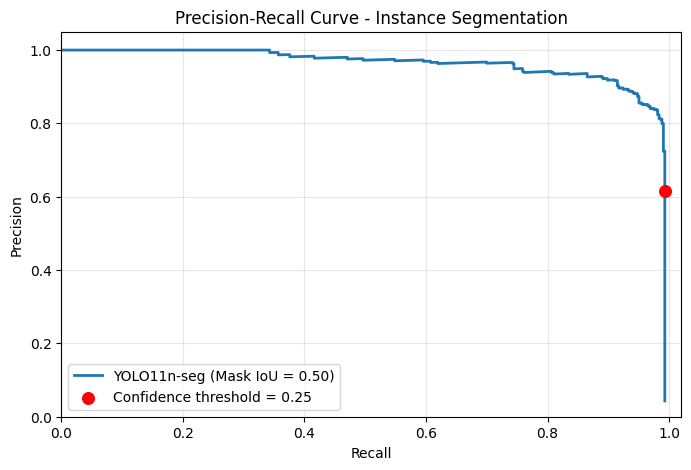

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    mask_recalls,
    mask_precisions,
    linewidth=2,
    label="YOLO11n-seg (Mask IoU = 0.50)"
)

# Operating point at confidence = 0.25
plt.scatter(
    recall_mask,
    precision_mask,
    color="red",
    s=70,
    label="Confidence threshold = 0.25",
    zorder=5
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Instance Segmentation")

plt.xlim(0, 1.02)
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### 4.4 Évaluation COCO-style des masques

On calcule Mask AP pour dix seuils de Mask IoU, de **0,50 à 0,95**, puis on fait la moyenne.

Ce score est plus exigeant que Mask AP@0.50 : il pénalise davantage les masques dont les contours ou la localisation ne correspondent pas assez précisément à la référence.

In [21]:
# Pré-calculer les IoU des masques prédits par rapport aux références
mask_detections = []

for img_idx, result in enumerate(segmentation_results):

    if result.masks is None:
        continue

    filename = os.path.basename(image_files[img_idx])
    gt_masks = ground_truth[filename]["masks"]

    pred_masks = result.masks.data.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()

    for pred_mask, score in zip(pred_masks, scores):

        pred_mask = pred_mask > 0.5

        if pred_mask.shape != gt_masks[0].shape:
            pred_mask = cv2.resize(
                pred_mask.astype(np.uint8),
                (gt_masks[0].shape[1], gt_masks[0].shape[0]),
                interpolation=cv2.INTER_NEAREST
            ).astype(bool)

        ious = np.array([
            calculate_mask_iou(pred_mask, gt_mask)
            for gt_mask in gt_masks
        ])

        mask_detections.append(
            (score, img_idx, ious)
        )

# Trier les masques selon leur score de confiance
mask_detections.sort(
    key=lambda x: x[0],
    reverse=True
)

# Calculer l'AP à partir des IoU pré-calculés
def mask_ap_from_cache(iou_threshold):

    matched = [set() for _ in image_files]

    tp_flags = []
    fp_flags = []

    for score, img_idx, ious in mask_detections:

        unmatched = [
            j for j in range(len(ground_truth[
                os.path.basename(image_files[img_idx])
            ]["masks"]))
            if j not in matched[img_idx]
        ]

        if unmatched:

            best_gt = max(unmatched, key=lambda j: ious[j])

            if ious[best_gt] >= iou_threshold:
                tp_flags.append(1)
                fp_flags.append(0)
                matched[img_idx].add(best_gt)
            else:
                tp_flags.append(0)
                fp_flags.append(1)

        else:
            tp_flags.append(0)
            fp_flags.append(1)

    total_gt = sum(
        len(ground_truth[os.path.basename(p)]["masks"])
        for p in image_files
    )

    tp_cum = np.cumsum(tp_flags)
    fp_cum = np.cumsum(fp_flags)

    recalls = tp_cum / total_gt
    precisions = tp_cum / (tp_cum + fp_cum)

    recall_levels = np.linspace(0, 1, 101)

    interpolated = []

    for r in recall_levels:
        valid = precisions[recalls >= r]
        interpolated.append(
            np.max(valid) if len(valid) else 0
        )

    return np.mean(interpolated)


# Évaluer les masques sur 10 seuils d'IoU
mask_iou_thresholds = np.arange(0.50, 0.96, 0.05)

mask_ap_values = []

for threshold in mask_iou_thresholds:

    ap = mask_ap_from_cache(float(threshold))
    mask_ap_values.append(ap)

    print(f"Mask AP@{threshold:.2f}: {ap:.4f}")

# Calculer la moyenne des AP sur les différents seuils
mask_map_50_95 = np.mean(mask_ap_values)

print("\nINSTANCE SEGMENTATION - COCO STYLE")
print(f"Mask mAP@0.50:0.95 = {mask_map_50_95:.4f}")

Mask AP@0.50: 0.9580
Mask AP@0.55: 0.9424
Mask AP@0.60: 0.9386
Mask AP@0.65: 0.8898
Mask AP@0.70: 0.8163
Mask AP@0.75: 0.7317
Mask AP@0.80: 0.5694
Mask AP@0.85: 0.4291
Mask AP@0.90: 0.0856
Mask AP@0.95: 0.0000

INSTANCE SEGMENTATION - COCO STYLE
Mask mAP@0.50:0.95 = 0.6361


**Lecture des résultats :** Mask AP@0.50 vaut **0,9580**, mais Mask mAP@0.50:0.95 descend à **0,6361**. Le modèle retrouve généralement les instances avec un recouvrement acceptable à 0,50, mais les performances diminuent fortement lorsque l’on exige des masques très précis.

## 5. Bilan du laboratoire

| Tâche | Résultat principal | Interprétation |
|---|---:|---|
| Classification | Accuracy = **0,9722** | Très bonne reconnaissance des dix classes |
| Détection | AP@0.50 = **0,9640** ; mAP@0.50:0.95 = **0,8587** | Bon niveau global, avec une baisse sous des seuils IoU plus stricts |
| Segmentation sémantique | IoU personne = **0,6478** ; IoU fond = **0,8932** ; mIoU = **0,7705** ; Dice = **0,7862** ; Pixel Accuracy = **0,9107** | Le recouvrement est meilleur pour le fond que pour les personnes |
| Segmentation d’instances | Mask AP@0.50 = **0,9580** ; Mask mAP@0.50:0.95 = **0,6361** | Les exigences élevées de précision des masques sont plus difficiles à satisfaire |

**Conclusion :** les métriques doivent être choisies selon l’unité évaluée : les images en classification, les boîtes en détection, les pixels en segmentation sémantique et les masques individuels en segmentation d’instances.